# Daily Temperature Forecasting
### CPTS 570 · Jiayu and Laman

**Question:** Does annual Fourier seasonality combined with short-term ARMA errors
improve daily mean temperature forecasting?

This demo follows the proposal: NOAA GSOD 2019–2024, chronological splits,
1-day and 7-day forecasts, component comparisons, and 95% prediction intervals.
All reported test results use models chosen before inspecting test performance.

## 1. Setup and reproducibility

From the repository root, create a Python environment and run:

```powershell
python -m pip install -r requirements.txt
python scripts/prepare_data.py
python scripts/validate_models.py
python scripts/summarize_validation.py
python scripts/evaluate_test.py
python scripts/summarize_test.py
jupyter lab notebooks/temperature_forecasting_demo.ipynb
```

The full validation search may take several minutes. The default notebook uses
saved experiment results and reconstructs a forecast from frozen parameters.
Raw/processed data are not tracked in Git; run preparation before opening this
notebook on another machine. Do not change the model choices after seeing 2024.


In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Image, Markdown
from statsmodels.tsa.statespace.sarimax import SARIMAX

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts/validate_models.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "scripts/validate_models.py").exists(), "Start from the project or notebooks directory"
sys.path.insert(0, str(ROOT / "scripts"))
from validate_models import fourier, metrics
pd.set_option("display.max_columns", 12)
print("Project:", ROOT)
print("Python:", sys.version.split()[0])


Project: C:\Users\laman.mirzayeva\Documents\ChatGPT\Project_570
Python: 3.13.12


## 2. Optional full reproduction

Leave `RUN_PIPELINE=False` for a quick demo. Set it to `True` to run preparation
and all analysis scripts. Existing cached experiments are reused. The scripts
never refit parameters during test forecasting. Changing source/data requires
reviewing cache validity, not silently reusing results.


In [2]:
RUN_PIPELINE = False
if RUN_PIPELINE:
    for script in ["prepare_data", "validate_models", "summarize_validation", "evaluate_test", "summarize_test"]:
        subprocess.run([sys.executable, str(ROOT / "scripts" / f"{script}.py")], cwd=ROOT, check=True)
print("Using saved results" if not RUN_PIPELINE else "Pipeline complete")


Using saved results


## 3. Station coverage and chronological splits

We use Pullman/Moscow Regional Airport, station **72785794129**. Spokane is the
audited backup. Temperatures are converted from Fahrenheit to Celsius. Calendar
gaps stay missing, and missing targets are excluded from evaluation.
GSOD dates represent UTC days. `TEMP_ATTRIBUTES` is a contributing observation
count, not a temperature quality flag.


In [3]:
data = pd.read_csv(ROOT / "data/processed/72785794129_daily.csv", parse_dates=["date"])
y = data.set_index("date").temperature_c.asfreq("D")
display(pd.read_csv(ROOT / "reports/station_coverage.csv"))
display(data.groupby("split").agg(calendar_days=("date", "size"), observed=("temperature_c", "count")))
print("Missing dates:", y[y.isna()].index.strftime("%Y-%m-%d").tolist())
assert len(y) == 2192 and y.index.is_unique


,station,year,expected_days,observed_days,missing_days,coverage_percent,longest_missing_run_days
0,72785794129,2019,365,365,0,100.000,0
1,72785794129,2020,366,366,0,100.000,0
2,72785794129,2021,365,364,1,99.726,1
3,72785794129,2022,365,365,0,100.000,0
4,72785794129,2023,365,365,0,100.000,0
5,72785794129,2024,366,366,0,100.000,0
6,72785024157,2019,365,365,0,100.000,0
7,72785024157,2020,366,366,0,100.000,0
8,72785024157,2021,365,365,0,100.000,0
9,72785024157,2022,365,365,0,100.000,0


,calendar_days,observed
split,,
test,366,366
train,1461,1460
validation,365,365


Missing dates: ['2021-12-31']


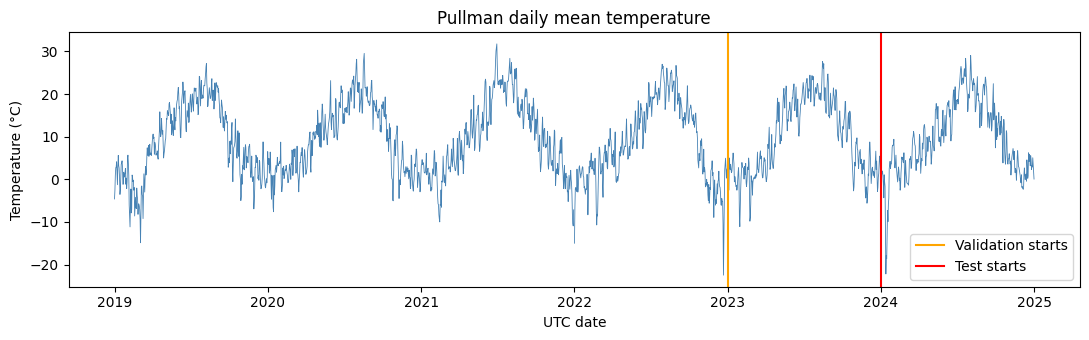

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(y.index, y, linewidth=.6, color="steelblue")
ax.axvline(pd.Timestamp("2023-01-01"), color="orange", label="Validation starts")
ax.axvline(pd.Timestamp("2024-01-01"), color="red", label="Test starts")
ax.set(title="Pullman daily mean temperature", ylabel="Temperature (°C)", xlabel="UTC date")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Model and selection

The combined model is

$$y_t=\beta_0+\sum_{k=1}^{K}\left[a_k\sin(2\pi kt/365.25)+b_k\cos(2\pi kt/365.25)\right]+u_t,$$

where $u_t$ follows ARMA$(p,q)$. Calendar time is measured from a fixed origin,
so leap days and missing observations do not shift seasonal phase. Regression
and error parameters are jointly estimated by maximum likelihood.

We searched $K=1,2,3$ and $p,q=0,1,2,3$. Training residual stationarity checks
did not justify differencing for the combined model. The nonseasonal comparison
searched $d=0,1$. One specification per family was chosen using the equal-weight
average of validation RMSE across the two horizons. All 83 candidate fits converged.


,family,model,mean_validation_rmse
0,arima,arima_K0_303,3.358006
1,combined,combined_K3_101,2.923120
2,persistence,persistence,3.844818
3,seasonal,seasonal_K3_000,3.666321


,family,horizon,n,rmse,mae
0,seasonal,1,365,3.661,2.896
1,seasonal,7,359,3.672,2.903
2,arima,1,365,2.259,1.763
3,arima,7,359,4.457,3.429
4,combined,1,365,2.169,1.703
5,combined,7,359,3.677,2.906
6,persistence,1,365,2.441,1.881
7,persistence,7,359,5.248,4.039


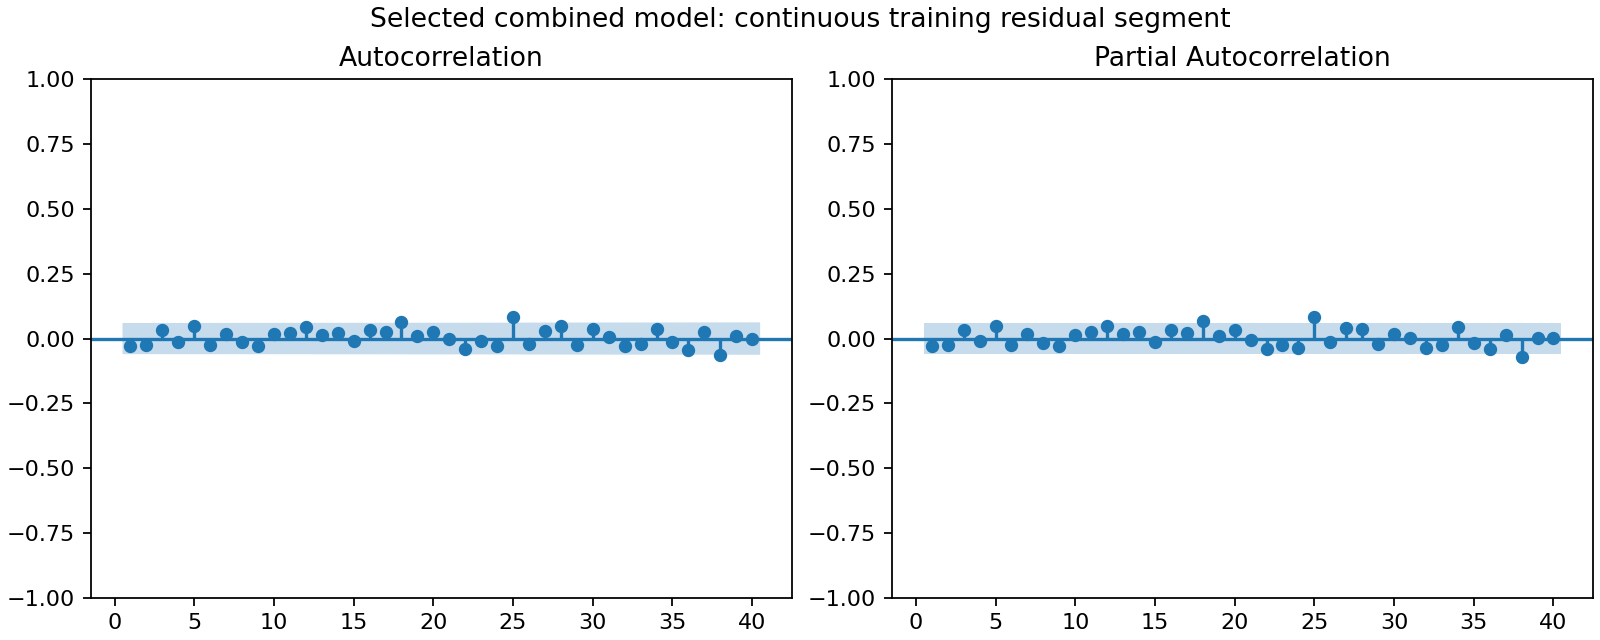

In [5]:
display(pd.read_csv(ROOT / "reports/validation/selected_models.csv"))
display(pd.read_csv(ROOT / "reports/validation/selected_metrics.csv")[["family","horizon","n","rmse","mae"]].round(3))
display(Image(filename=str(ROOT / "reports/validation/training_residual_acf_pacf.png")))


## 5. Frozen held-out evaluation

After selection, refit on **2019–2023** and freeze parameters. Issue forecasts at
daily origins before revealing the next observation; then update the latent state.
Use identical origins and observed targets across models. The test contains
366 one-day forecasts and 360 seven-day forecasts (seven-day targets begin January 7).
The first origin is December 31, 2023. Publication delays are not modeled.


{'selection_sha256': 'c4772623daeb03eb37671e99f23af24f7e44cbacd3ccb2922a830b1722387412',
 'fit_end': '2023-12-31',
 'test_start': '2024-01-01',
 'test_end': '2024-12-31',
 'specifications': [{'model': 'arima_K0_303',
   'family': 'arima',
   'k': 0,
   'p': 3,
   'd': 0,
   'q': 3},
  {'model': 'combined_K3_101',
   'family': 'combined',
   'k': 3,
   'p': 1,
   'd': 0,
   'q': 1},
  {'model': 'seasonal_K3_000',
   'family': 'seasonal',
   'k': 3,
   'p': 0,
   'd': 0,
   'q': 0}],
 'horizons': [1, 7],
 'refit_during_test': False,
 'origin_start': '2023-12-31',
 'interval_alpha': 0.05}

,family,horizon,n,rmse,mae
0,arima,1,366,2.486,1.932
1,arima,7,360,4.903,3.787
2,combined,1,366,2.405,1.815
3,combined,7,360,4.019,3.022
4,seasonal,1,366,4.003,2.995
5,seasonal,7,360,4.034,3.028
6,persistence,1,366,2.578,1.978
7,persistence,7,360,5.556,4.371


,horizon,coverage,mean_width
2,1,0.937,9.295
3,7,0.956,14.856


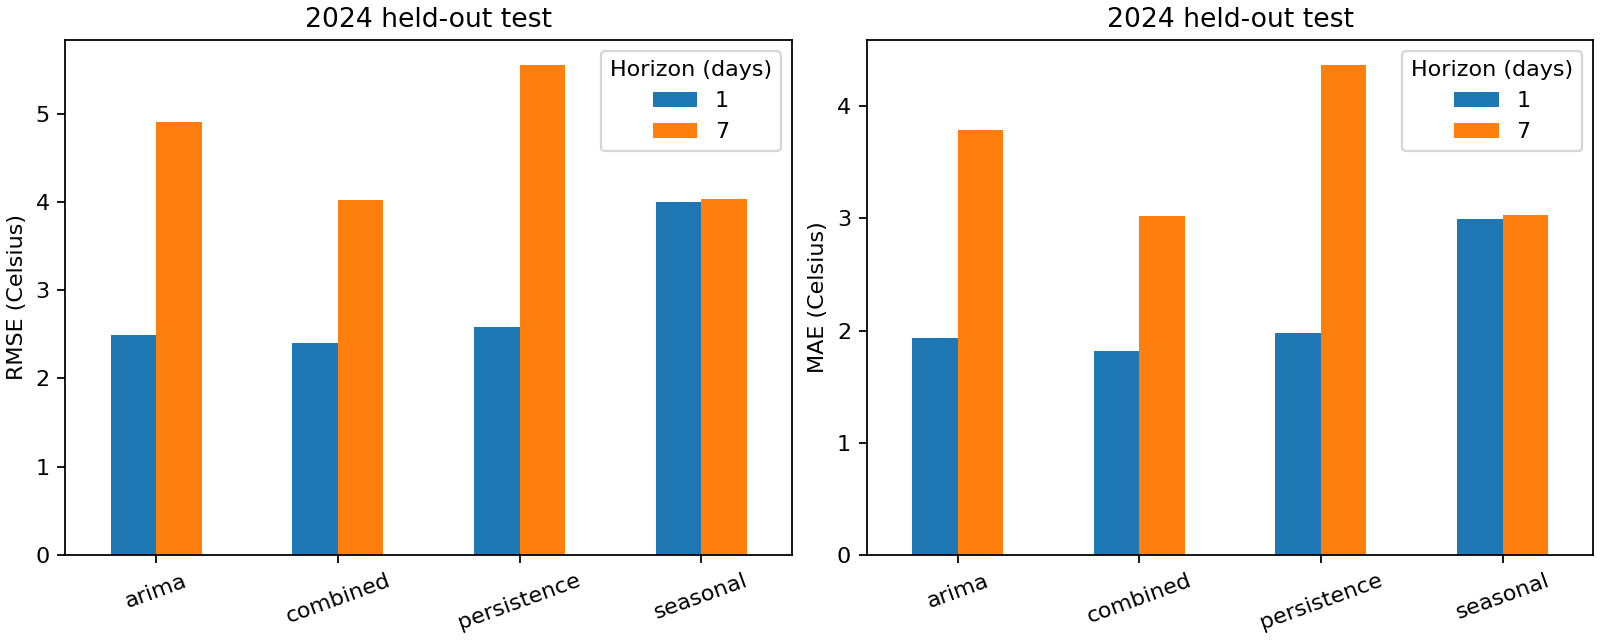

In [6]:
protocol = json.loads((ROOT / "reports/test/frozen_protocol.json").read_text())
display(protocol)
test_scores = pd.read_csv(ROOT / "reports/test/test_metrics.csv")
display(test_scores[["family","horizon","n","rmse","mae"]].round(3))
display(test_scores.loc[test_scores.family.eq("combined"), ["horizon","coverage","mean_width"]].round(3))
display(Image(filename=str(ROOT / "reports/test/test_accuracy.png")))


## 6. Reconstruct an individual forecast

Change `ORIGIN` to any test forecast origin through December 24, 2024. We load
the parameters fitted through 2023 and filter **only observations up to the origin**.
Known future calendar terms are allowed. Future temperatures are used only
after forecasting, to display observed targets. This reproduces saved rolling
forecasts rather than fitting a model on test observations.


In [7]:
ORIGIN = pd.Timestamp("2024-07-01")
assert pd.Timestamp("2023-12-31") <= ORIGIN <= pd.Timestamp("2024-12-24")
meta = json.loads((ROOT / "reports/test/combined_K3_101_fit.json").read_text())
history = y.loc[:ORIGIN]
future = pd.date_range(ORIGIN + pd.Timedelta(days=1), periods=7)
model = SARIMAX(history.to_numpy(), exog=fourier(history.index, meta["k"]),
                order=(meta["p"],meta["d"],meta["q"]),
                enforce_stationarity=True, enforce_invertibility=True)
filtered = model.filter(meta["params"])
fc = filtered.get_forecast(steps=7, exog=fourier(future, meta["k"]))
interval = np.asarray(fc.conf_int(alpha=.05))
forecast = pd.DataFrame({"prediction": np.asarray(fc.predicted_mean),
                         "lower": interval[:,0], "upper": interval[:,1]}, index=future)
forecast["observed_after_forecast"] = y.reindex(future)
display(forecast.iloc[[0,6]].round(3))
saved = pd.read_csv(ROOT / "reports/test/combined_K3_101.csv", parse_dates=["origin","target"])
for h in (1,7):
    row = saved[(saved.origin == ORIGIN) & (saved.horizon == h)].iloc[0]
    np.testing.assert_allclose(forecast.iloc[h-1][["prediction","lower","upper"]].to_numpy(),
                               row[["prediction","lower","upper"]].to_numpy(dtype=float), atol=1e-8)
print("Reconstructed forecasts and intervals match saved evaluation.")


,prediction,lower,upper,observed_after_forecast
2024-07-02,18.438,13.791,23.086,18.722
2024-07-08,19.747,12.319,27.175,24.556


Reconstructed forecasts and intervals match saved evaluation.


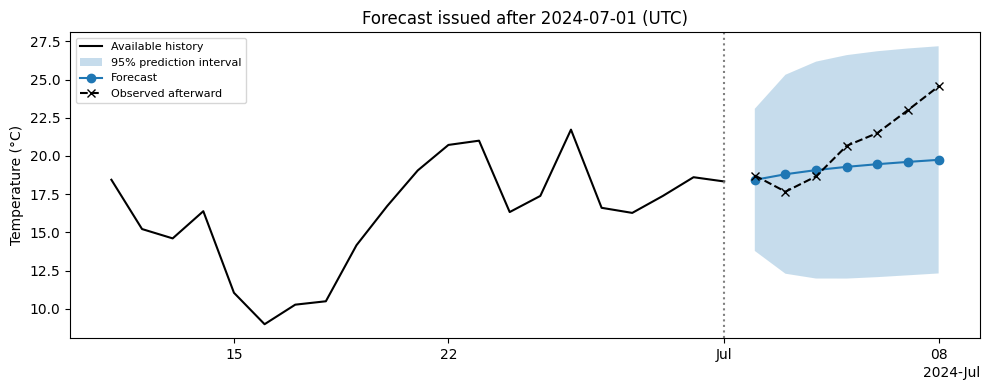

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
recent = history.iloc[-21:]
ax.plot(recent.index, recent, color="black", label="Available history")
ax.fill_between(future, forecast.lower, forecast.upper, alpha=.25, label="95% prediction interval")
ax.plot(future, forecast.prediction, "o-", label="Forecast")
ax.plot(future, forecast.observed_after_forecast, "x--", color="black", label="Observed afterward")
ax.axvline(ORIGIN, color="gray", linestyle=":")
ax.set(title=f"Forecast issued after {ORIGIN.date()} (UTC)", ylabel="Temperature (°C)")
locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 7. Seasonal errors and uncertainty limitations

The combined model has the lowest test RMSE/MAE at both horizons, but its
seven-day RMSE advantage over seasonal regression is only about **0.015°C**.
Validation slightly favored seasonal regression at seven days. We do not claim
statistical significance from this descriptive comparison.

One-day interval coverage is **93.7%**, below nominal 95%; seven-day coverage is
**95.6%**. Refitted combined residuals pass the two Ljung–Box checks, but reject
normality and show evidence of changing conditional variance. Gaussian intervals
omit parameter uncertainty. We report these limitations without retuning on 2024.
Winter is particularly difficult. One station, one test year, and dependent
overlapping seven-day errors limit generalization.


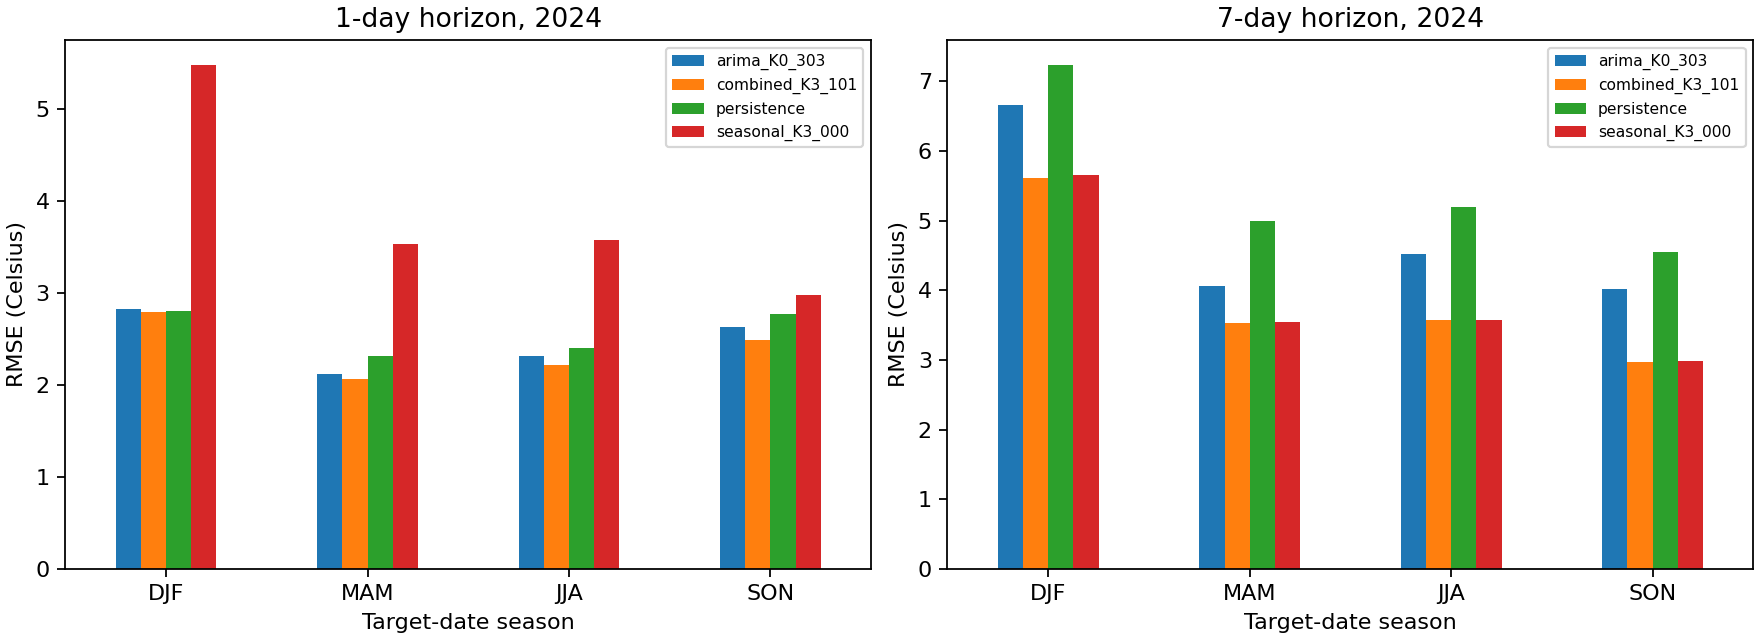

,model,continuous_segment_n,ljung_box_p,jarque_bera_p,arch_lm_p
0,arima_K0_303,1065,"{'14': 0.33665521522919, '30': 0.0209673033240...",1.794389e-09,2.567141e-01
1,combined_K3_101,1065,"{'14': 0.458666617417452, '30': 0.157853461510...",5.116003e-13,2.536614e-02
2,seasonal_K3_000,1065,"{'14': 2.8935184228895403e-209, '30': 1.768822...",4.968232e-06,1.598761e-73


In [9]:
display(Image(filename=str(ROOT / "reports/test/test_errors_by_season.png")))
display(pd.read_json(ROOT / "reports/test/refit_diagnostics.json"))


## 8. Verification and references

The protocol tests check phase continuity across leap days, exact horizon
alignment, frozen parameters, and that altering future observations cannot
change earlier forecasts. File hashes link results to data and analysis code.

- [NOAA GSOD data](https://www.ncei.noaa.gov/data/global-summary-of-the-day/access/)
- [NOAA field documentation](https://www.ncei.noaa.gov/data/global-summary-of-the-day/doc/readme.txt)
- [Dynamic harmonic regression, Forecasting: Principles and Practice](https://otexts.com/fpp3/dhr.html)
- [statsmodels state updates](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.statespace.sarimax.SARIMAXResults.extend.html)

The paper, presentation, and GitHub publication remain separate deliverables.


In [10]:
hashes = json.loads((ROOT / "reports/test/reproduction_hashes.json").read_text())
for relative, expected in hashes.items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected, relative
subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "scripts", "-p", "test_forecasting.py"],
               cwd=ROOT, check=True)
print("Hashes and forecasting protocol tests passed.")


Hashes and forecasting protocol tests passed.
